# CrackSense — What Happens Inside SegFormer

**Standalone explanation notebook.** No training, no dataset loading.
Just loads the trained `best.pt` checkpoint and shows exactly what happens
to one image at every stage — from raw pixels to binary crack mask.

Includes a detailed explanation of how Otsu thresholding works.

## 1. Load the Trained Model

In [9]:
import os, sys, io, re
import numpy as np
import cv2
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerForSemanticSegmentation
from PIL import Image

# ---- Config (must match what the model was trained with) ----
MODEL_NAME = "nvidia/mit-b2"
IMG_SIZE = 256
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Locate the checkpoint file from a few common locations to avoid FileNotFoundError
possible_ckpts = [
    os.path.join("B2_Exp", "checkpoints", "latest.pt"),
    os.path.join("B2_Exp", "checkpoints", "best.pt"),
    os.path.join("checkpoints", "latest.pt"),
    os.path.join("checkpoints", "best.pt"),
]
CHECKPOINT_PATH = None
for p in possible_ckpts:
    if os.path.exists(p):
        CHECKPOINT_PATH = p
        break
if CHECKPOINT_PATH is None:
    raise FileNotFoundError(f"Could not find checkpoint. Tried: {possible_ckpts}")

print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_properties(0).name}")

# ---- Load model architecture ----
model = SegformerForSemanticSegmentation.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "background", 1: "crack"},
    label2id={"background": 0, "crack": 1},
    ignore_mismatched_sizes=True,
)

# ---- Load trained weights ----
ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
state_dict = ckpt["model_state_dict"]

def normalize_checkpoint_key(key):
    key = re.sub(r"^segformer\.stages\.(\d+)\.patch_embeddings\.", r"segformer.encoder.patch_embeddings.\1.", key)
    key = re.sub(r"^segformer\.stages\.(\d+)\.blocks\.(\d+)\.", r"segformer.encoder.block.\1.\2.", key)
    key = re.sub(r"^segformer\.stages\.(\d+)\.layer_norm\.", r"segformer.encoder.layer_norm.\1.", key)
    key = key.replace(".layernorm_before.", ".layer_norm_1.")
    key = key.replace(".layernorm_after.", ".layer_norm_2.")
    key = key.replace(".attention.q_proj.", ".attention.self.query.")
    key = key.replace(".attention.k_proj.", ".attention.self.key.")
    key = key.replace(".attention.v_proj.", ".attention.self.value.")
    key = key.replace(".attention.o_proj.", ".attention.output.dense.")
    key = key.replace(".attention.sequence_reduction.sequence_reduction.", ".attention.self.sr.")
    key = key.replace(".attention.sequence_reduction.layer_norm.", ".attention.self.layer_norm.")
    key = key.replace(".mlp.fc1.", ".mlp.dense1.")
    key = key.replace(".mlp.fc2.", ".mlp.dense2.")
    key = key.replace("decode_head.linear_projections.", "decode_head.linear_c.")
    return key

state_dict = {normalize_checkpoint_key(key): value for key, value in state_dict.items()}
model.load_state_dict(state_dict)
model.to(DEVICE)
model.eval()

# ---- Read checkpoint info ----
saved_config = ckpt.get("config", {})
best_dice = ckpt.get("best_dice", "?")
best_epoch = ckpt.get("epoch", "?")
calibrated_threshold = float(ckpt.get("best_threshold", 0.50))

print(f"\nCheckpoint loaded: {CHECKPOINT_PATH}")
print(f"  Trained model:    {saved_config.get('MODEL_NAME', MODEL_NAME)}")
print(f"  Best epoch:       {best_epoch}")
print(f"  Best val Dice:    {best_dice}")
print(f"  Calibrated threshold: {calibrated_threshold}")

# ---- Helper from training notebook ----
def binary_logits_from_two_class(logits):
    """For a 2-class model, crack logit - background logit = binary crack logit."""
    return logits[:, 1] - logits[:, 0]

# ---- Inference preprocessing (same as training notebook) ----
infer_tf = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

print("\nReady. Upload an image below to see the full pipeline.")

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b2 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Checkpoint loaded: checkpoints\latest.pt
  Trained model:    nvidia/mit-b2
  Best epoch:       39
  Best val Dice:    0.7909939782085184
  Calibrated threshold: 0.5

Ready. Upload an image below to see the full pipeline.


## 2. Load an Image

Loaded: WhatsApp Image 2026-08-17 at 22.19.55.jpeg
Size: 408 × 612 × 3


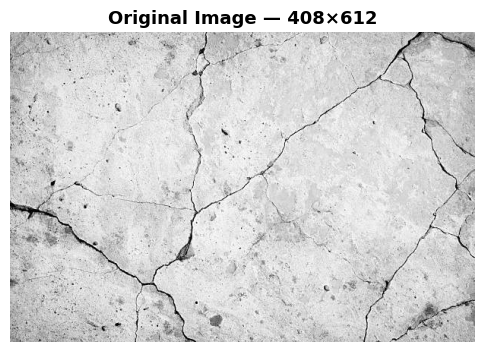

In [10]:
# --- Set your image path here ---
IMAGE_PATH = r"WhatsApp Image 2026-08-17 at 22.19.55.jpeg"  # <-- change this to your image
# If the path doesn't exist, try a few common fallbacks and then auto-discover an image in the dataset
if not os.path.exists(IMAGE_PATH):
    fallback_candidates = [
        r"WhatsApp Image 2026-08-17 at 22.19.55.jpeg",
        r"WhatsApp Image 2026-08-17 at 22.19.55.jpeg",
    ]
    for p in fallback_candidates:
        if os.path.exists(p):
            IMAGE_PATH = p
            print(f"Using fallback image: {IMAGE_PATH}")
            break
    else:
        # search inside the data folder for any image and pick the first one
        found = None
        for root, dirs, files in os.walk(os.path.join(os.getcwd(), 'data')):
            for fn in files:
                if fn.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')):
                    found = os.path.join(root, fn)
                    break
            if found:
                IMAGE_PATH = found
                print(f"Auto-discovered image: {IMAGE_PATH}")
                break
        if not os.path.exists(IMAGE_PATH):
            raise FileNotFoundError(f"Could not find image. Tried: {IMAGE_PATH} and fallbacks.")

# Load it
pil_img = Image.open(IMAGE_PATH).convert("RGB")
np_img = np.array(pil_img)
orig_h, orig_w = np_img.shape[:2]

print(f"Loaded: {IMAGE_PATH}")
print(f"Size: {orig_h} × {orig_w} × 3")

plt.figure(figsize=(6, 6))
plt.imshow(np_img)
plt.title(f"Original Image — {orig_h}×{orig_w}", fontsize=13, fontweight="bold")
plt.axis("off")
plt.show()


## 3. Preprocessing — What the Model Actually Receives

The model doesn't see the raw image. It sees a resized, normalized tensor.
Here's each step.

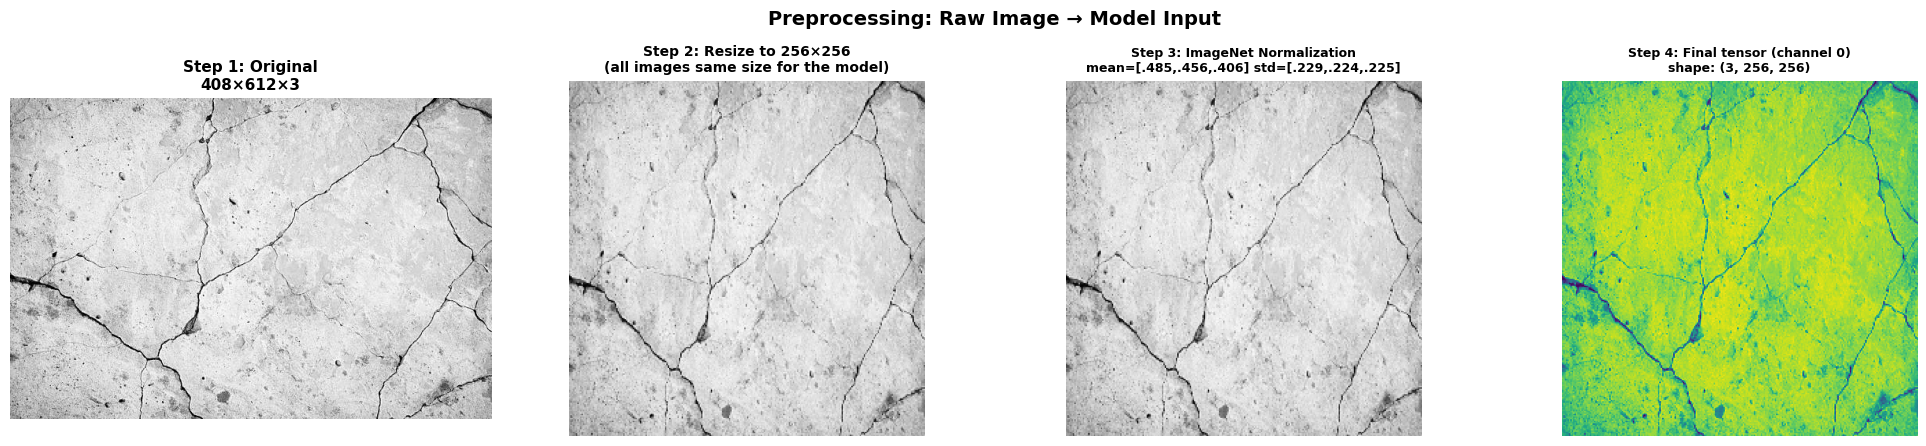

Original:    408 × 612 × 3  (uint8, 0-255)
Resized:     256 × 256 × 3  (uint8, 0-255)
Normalized:  256 × 256 × 3  (float32, shifted to ImageNet distribution)
Final tensor: (1, 3, 256, 256)  (batch × channels × height × width)

Why ImageNet normalization?
  The MiT-B2 encoder was pretrained on ImageNet with these exact mean/std values.
  If we don't match them, the pretrained weights receive out-of-distribution inputs
  and perform badly — like speaking English to someone trained only in Japanese.


In [11]:
# Step 1: Resize
resized = A.Resize(IMG_SIZE, IMG_SIZE)(image=np_img)["image"]

# Step 2: Normalize (ImageNet mean/std — because the encoder was pretrained on ImageNet)
mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])
normalized_float = (resized.astype(np.float32) / 255.0 - mean) / std

# Step 3: To tensor
augmented = infer_tf(image=np_img)
tensor_img = augmented["image"]  # shape: (3, 256, 256)
input_tensor = tensor_img.unsqueeze(0).to(DEVICE)  # shape: (1, 3, 256, 256)

# For display: undo normalization
disp_norm = np.clip(tensor_img.numpy().transpose(1, 2, 0) * std + mean, 0, 1)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

axes[0].imshow(np_img)
axes[0].set_title(f"Step 1: Original\n{orig_h}×{orig_w}×3", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(resized)
axes[1].set_title(f"Step 2: Resize to {IMG_SIZE}×{IMG_SIZE}\n(all images same size for the model)", fontsize=10, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(disp_norm)
axes[2].set_title("Step 3: ImageNet Normalization\nmean=[.485,.456,.406] std=[.229,.224,.225]", fontsize=9, fontweight="bold")
axes[2].axis("off")

axes[3].imshow(tensor_img.numpy()[0], cmap="viridis")
axes[3].set_title(f"Step 4: Final tensor (channel 0)\nshape: {tuple(tensor_img.shape)}", fontsize=9, fontweight="bold")
axes[3].axis("off")

plt.suptitle("Preprocessing: Raw Image → Model Input", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Original:    {orig_h} × {orig_w} × 3  (uint8, 0-255)")
print(f"Resized:     {IMG_SIZE} × {IMG_SIZE} × 3  (uint8, 0-255)")
print(f"Normalized:  {IMG_SIZE} × {IMG_SIZE} × 3  (float32, shifted to ImageNet distribution)")
print(f"Final tensor: {tuple(input_tensor.shape)}  (batch × channels × height × width)")
print(f"\nWhy ImageNet normalization?")
print(f"  The MiT-B2 encoder was pretrained on ImageNet with these exact mean/std values.")
print(f"  If we don't match them, the pretrained weights receive out-of-distribution inputs")
print(f"  and perform badly — like speaking English to someone trained only in Japanese.")


## 4. Inside the Encoder — 4 Hierarchical Stages

The MiT-B2 encoder processes the image through 4 stages.
Each stage produces a feature map at a different resolution.
Early stages see fine details (edges), later stages see broad context (semantics).

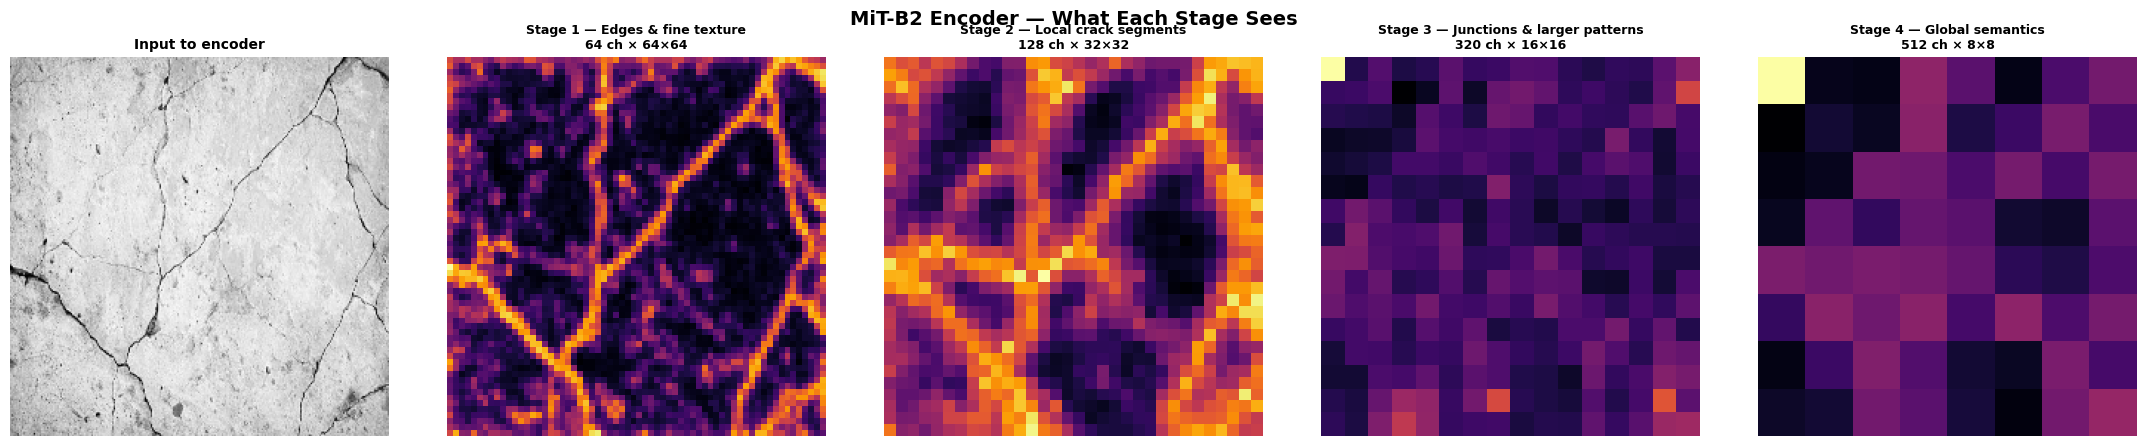


  Stage 1 — Edges & fine texture
  Tensor shape: 1 × 64 channels × 64 × 64
  Captures low-level features: edges, gradients, the fine linear texture
of a crack against smooth concrete. Highest spatial resolution.
Think of it as: 'what does each small patch look like?'

  Stage 2 — Local crack segments
  Tensor shape: 1 × 128 channels × 32 × 32
  Slightly larger receptive field. Detects short connected crack segments,
small structural features, local patterns.
Think of it as: 'do nearby patches form a line or a blob?'

  Stage 3 — Junctions & larger patterns
  Tensor shape: 1 × 320 channels × 16 × 16
  Captures crack junctions, branching points, larger contextual patterns.
Can distinguish a crack from a similar-looking mortar line or shadow.
Think of it as: 'what is this region doing?'

  Stage 4 — Global semantics
  Tensor shape: 1 × 512 channels × 8 × 8
  The deepest, most abstract representation. Understands 'this whole area
reads as cracked wall' vs 'this is just dirt/shadow/texture

In [12]:
# Run the model to obtain encoder hidden states for visualization
with torch.no_grad():
    with torch.amp.autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
        outputs_enc = model(pixel_values=input_tensor, output_hidden_states=True, return_dict=True)
        hidden_states = getattr(outputs_enc, 'hidden_states', getattr(outputs_enc, 'encoder_hidden_states', None))
        if hidden_states is None:
            raise RuntimeError('Model did not return hidden states. Ensure the model supports output_hidden_states=True.')

stage_info = [
    ("Stage 1 — Edges & fine texture",
     "Captures low-level features: edges, gradients, the fine linear texture\n"
     "of a crack against smooth concrete. Highest spatial resolution.\n"
     "Think of it as: 'what does each small patch look like?'"),

    ("Stage 2 — Local crack segments",
     "Slightly larger receptive field. Detects short connected crack segments,\n"
     "small structural features, local patterns.\n"
     "Think of it as: 'do nearby patches form a line or a blob?'"),

    ("Stage 3 — Junctions & larger patterns",
     "Captures crack junctions, branching points, larger contextual patterns.\n"
     "Can distinguish a crack from a similar-looking mortar line or shadow.\n"
     "Think of it as: 'what is this region doing?'"),

    ("Stage 4 — Global semantics",
     "The deepest, most abstract representation. Understands 'this whole area\n"
     "reads as cracked wall' vs 'this is just dirt/shadow/texture.'\n"
     "Think of it as: 'what IS this part of the image?'"),
]

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))

# Show input
axes[0].imshow(disp_norm)
axes[0].set_title("Input to encoder", fontsize=10, fontweight="bold")
axes[0].axis("off")

dim_table = []
for idx, (hs, (title, _)) in enumerate(zip(hidden_states, stage_info)):
    feat = hs[0]  # (C, H, W)
    # Aggregate channels by L2 norm — gives a 2D "activation intensity" map
    activation = feat.norm(dim=0).cpu().numpy()
    C, H, W = feat.shape
    dim_table.append((idx + 1, H, W, C))

    axes[idx + 1].imshow(activation, cmap="inferno")
    axes[idx + 1].set_title(f"{title}\n{C} ch × {H}×{W}", fontsize=9, fontweight="bold")
    axes[idx + 1].axis("off")

plt.suptitle("MiT-B2 Encoder — What Each Stage Sees", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Print detailed descriptions
for idx, ((title, desc), (_, H, W, C)) in enumerate(zip(stage_info, dim_table)):
    print(f"\n{'='*60}")
    print(f"  {title}")
    print(f"  Tensor shape: 1 × {C} channels × {H} × {W}")
    print(f"{'='*60}")
    print(f"  {desc}")

# Resolution table
print(f"\n\n  The key pattern — spatial resolution shrinks, semantic depth grows:")
print(f"  ┌───────────┬────────┬───────┬──────────┐")
print(f"  │   Stage   │ Height │ Width │ Channels │")
print(f"  ├───────────┼────────┼───────┼──────────┤")
for s, H, W, C in dim_table:
    print(f"  │  Stage {s}  │   {H:>3} │  {W:>3} │     {C:>3}  │")
print(f"  └───────────┴────────┴───────┴──────────┘")
print(f"\n  Stage 1: lots of spatial detail, shallow understanding")
print(f"  Stage 4: little spatial detail, deep semantic understanding")
print(f"  The decoder's job is to combine BOTH — so the final mask")
print(f"  is both spatially precise AND semantically correct.")


## 5. Decoder → Probability Map

The MLP decoder takes all 4 stage outputs, fuses them, and produces
a **continuous probability** for each pixel: how likely is it to be a crack?

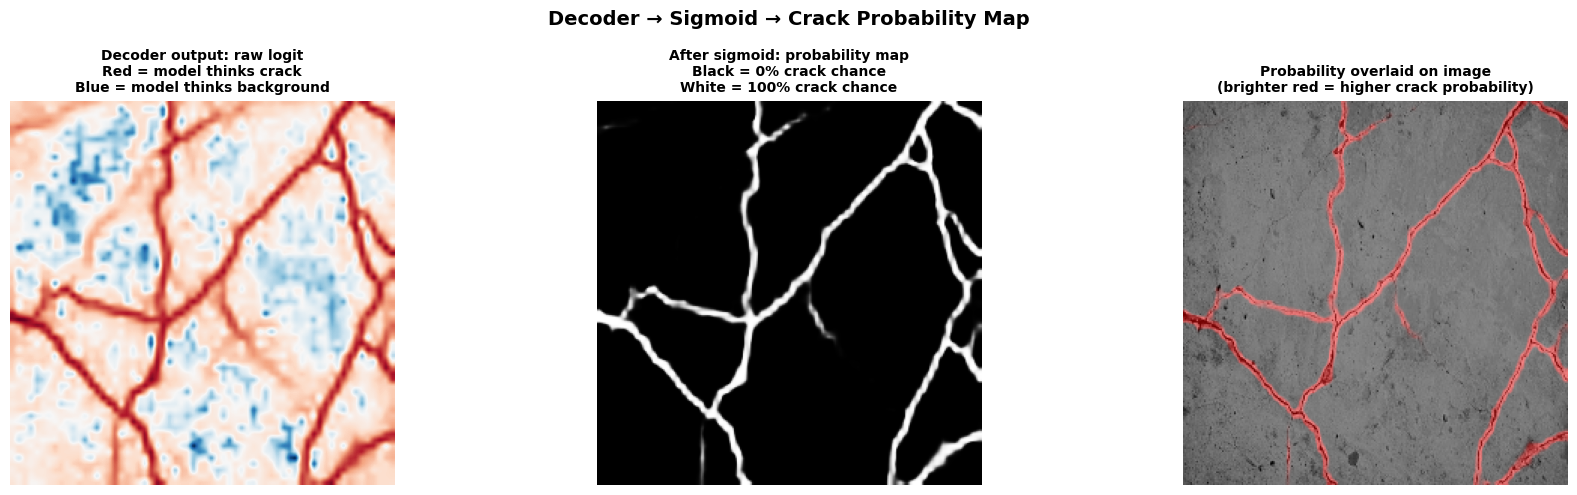

  Raw decoder output shape: (1, 2, 64, 64)
  After upsampling:         (1, 2, 256, 256)
  Binary logit range:       [-37.75, 9.42]
  After sigmoid (prob):     [0.0000, 0.9999]
  Mean probability:         0.0775

  IMPORTANT: This is NOT a binary mask yet.
  Every pixel has a probability between 0 and 1.
  We still need to decide: above what probability do we call it 'crack'?
  That decision is the THRESHOLD — explained next.


In [13]:
# Full forward pass to get logits
with torch.no_grad():
    with torch.amp.autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
        outputs = model(pixel_values=input_tensor, output_hidden_states=True)
        logits = outputs.logits  # shape: (1, 2, H/4, W/4)

# Upsample to full input size
logits_full = F.interpolate(logits, size=(IMG_SIZE, IMG_SIZE),
                            mode="bilinear", align_corners=False)

# Convert 2-class logits to single binary crack score
binary_logit = binary_logits_from_two_class(logits_full.float())  # (1, H, W)

# Sigmoid turns logit into probability (0 to 1)
prob_map = torch.sigmoid(binary_logit)[0].cpu().numpy()  # (H, W)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Decoder output (logit — can be negative or positive)
logit_np = binary_logit[0].cpu().numpy()
axes[0].imshow(logit_np, cmap="RdBu_r")
axes[0].set_title("Decoder output: raw logit\n"
                  "Red = model thinks crack\n"
                  "Blue = model thinks background", fontsize=10, fontweight="bold")
axes[0].axis("off")

# Probability map (after sigmoid — always 0 to 1)
axes[1].imshow(prob_map, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("After sigmoid: probability map\n"
                  "Black = 0% crack chance\n"
                  "White = 100% crack chance", fontsize=10, fontweight="bold")
axes[1].axis("off")

# Overlay
overlay = disp_norm.copy()
red_overlay = np.zeros_like(overlay)
red_overlay[:, :, 0] = prob_map
axes[2].imshow(np.clip(overlay * 0.55 + red_overlay * 0.45, 0, 1))
axes[2].set_title("Probability overlaid on image\n(brighter red = higher crack probability)", fontsize=10, fontweight="bold")
axes[2].axis("off")

plt.suptitle("Decoder → Sigmoid → Crack Probability Map", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"  Raw decoder output shape: {tuple(logits.shape)}")
print(f"  After upsampling:         {tuple(logits_full.shape)}")
print(f"  Binary logit range:       [{logit_np.min():.2f}, {logit_np.max():.2f}]")
print(f"  After sigmoid (prob):     [{prob_map.min():.4f}, {prob_map.max():.4f}]")
print(f"  Mean probability:         {prob_map.mean():.4f}")
print(f"\n  IMPORTANT: This is NOT a binary mask yet.")
print(f"  Every pixel has a probability between 0 and 1.")
print(f"  We still need to decide: above what probability do we call it 'crack'?")
print(f"  That decision is the THRESHOLD — explained next.")


## 6. How Otsu Thresholding Works — Step by Step

This is the key section. We explain exactly how Otsu decides the threshold,
with the actual math and the actual numbers from our probability map.

**The core question:** we have a probability map where each pixel is a number
between 0 and 1. We need to draw a line: above = crack, below = background.
Where should that line be?

**Two approaches:**
- **Calibrated threshold:** sweep many thresholds on the validation set, pick the one
  that maximizes Dice score globally. Same value for every image.
- **Otsu threshold:** for each individual image, look at its probability distribution
  and automatically find the best split point. Different for every image.

HOW OTSU WORKS — on our actual probability map

STEP 1: Look at the probability distribution

  Every pixel has a crack probability between 0 and 1.
  Most pixels are background (probability near 0).
  A few pixels are crack (probability near 1).
  The histogram shows this distribution.



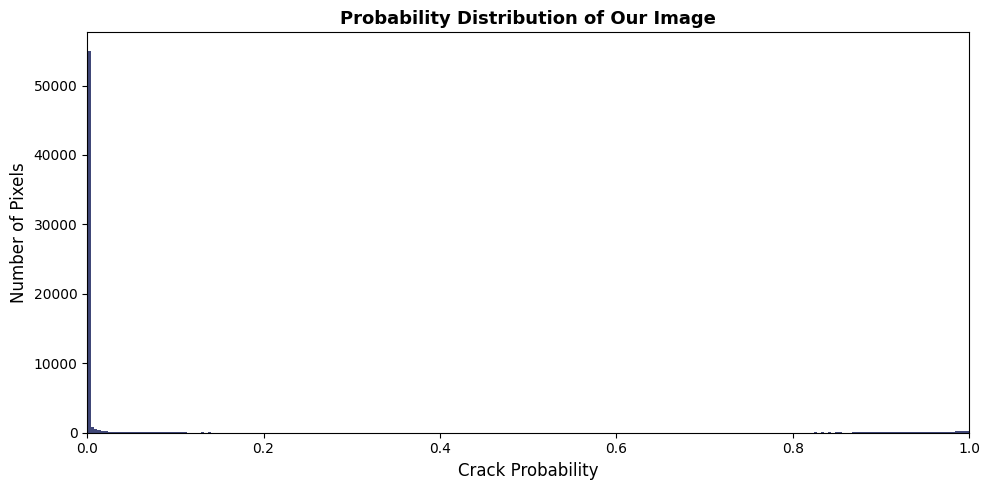

  Total pixels: 65,536
  Pixels with prob < 0.5: 60,414 (92.2%)
  Pixels with prob ≥ 0.5: 5,122 (7.8%)

STEP 2: What Otsu does

  Otsu tries EVERY possible threshold T from 0 to 1.
  For each T, it splits the pixels into two groups:
    Group A: pixels with probability ≤ T  (background)
    Group B: pixels with probability > T  (crack)

  For each split, it asks:
    "How different are the average probabilities of group A vs group B?"

  This is measured by the "between-class variance":
    σ² = wA × wB × (μA − μB)²

  where:
    wA = fraction of pixels in group A
    wB = fraction of pixels in group B
    μA = mean probability of group A
    μB = mean probability of group B

  Otsu picks the T that MAXIMIZES this variance.
  In other words: the split that makes the two groups
  as different from each other as possible.

STEP 3: The result
  Otsu threshold (OpenCV):  0.4235
  Otsu threshold (manual):  0.4250
  (These should be very close — both use the same algorithm)



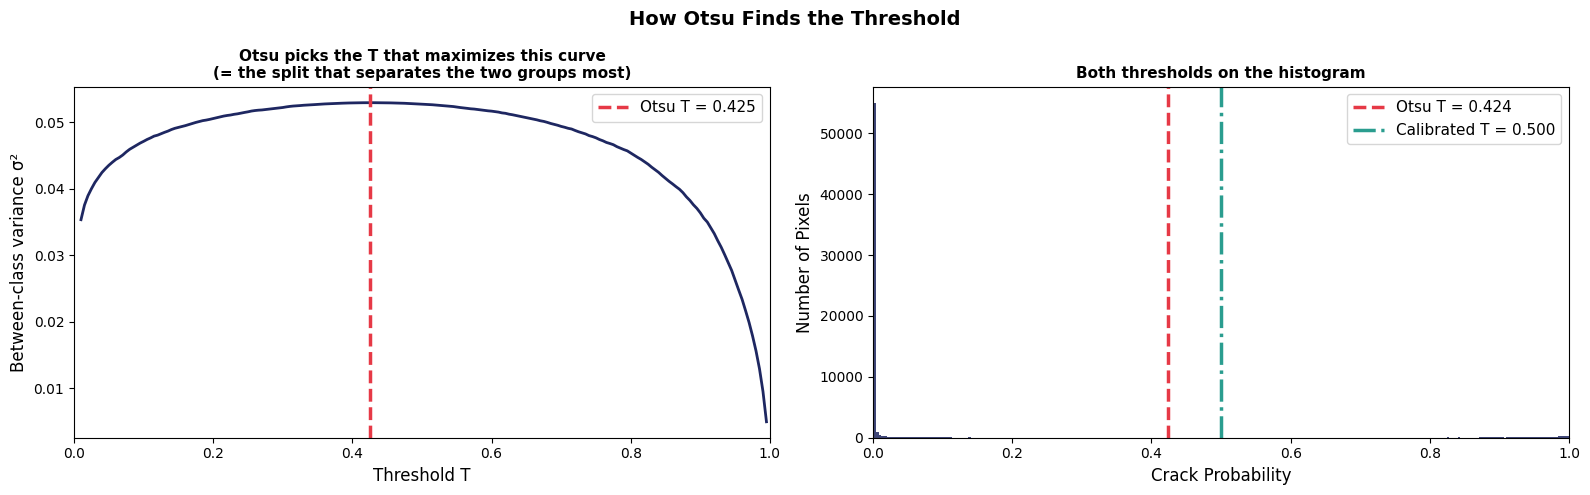


  At Otsu T = 0.424:
    Background group: 60,125 pixels, mean prob = 0.0085
    Crack group:      5,411 pixels, mean prob = 0.8446
    Separation:       |0.0085 − 0.8446| = 0.8361

  KEY POINT — Otsu does NOT use any fixed position.
  It does NOT assume the threshold should be 0.5 or 0.8 or any specific value.
  It looks at THIS specific image's probability distribution and finds
  the split point where background and crack pixels are maximally separated.

  Different images → different distributions → different Otsu thresholds.

  This is why it's called "adaptive" — it adapts to each image individually,
  unlike the calibrated threshold which is the same for every image.



In [14]:
# ============================================================
# OTSU THRESHOLDING — EXPLAINED WITH REAL NUMBERS
# ============================================================

print("=" * 65)
print("HOW OTSU WORKS — on our actual probability map")
print("=" * 65)

# Step 1: Look at the distribution
print("""
STEP 1: Look at the probability distribution

  Every pixel has a crack probability between 0 and 1.
  Most pixels are background (probability near 0).
  A few pixels are crack (probability near 1).
  The histogram shows this distribution.
""")

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
counts, bin_edges, patches = ax.hist(prob_map.ravel(), bins=256, range=(0, 1),
                                      color="#1E2761", edgecolor="none", alpha=0.85)
ax.set_xlabel("Crack Probability", fontsize=12)
ax.set_ylabel("Number of Pixels", fontsize=12)
ax.set_title("Probability Distribution of Our Image", fontsize=13, fontweight="bold")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

total_pixels = prob_map.size
bg_pixels = (prob_map < 0.5).sum()
cr_pixels = (prob_map >= 0.5).sum()
print(f"  Total pixels: {total_pixels:,}")
print(f"  Pixels with prob < 0.5: {bg_pixels:,} ({100*bg_pixels/total_pixels:.1f}%)")
print(f"  Pixels with prob ≥ 0.5: {cr_pixels:,} ({100*cr_pixels/total_pixels:.1f}%)")

# Step 2: Otsu's algorithm
print("""
STEP 2: What Otsu does

  Otsu tries EVERY possible threshold T from 0 to 1.
  For each T, it splits the pixels into two groups:
    Group A: pixels with probability ≤ T  (background)
    Group B: pixels with probability > T  (crack)

  For each split, it asks:
    "How different are the average probabilities of group A vs group B?"

  This is measured by the "between-class variance":
    σ² = wA × wB × (μA − μB)²

  where:
    wA = fraction of pixels in group A
    wB = fraction of pixels in group B
    μA = mean probability of group A
    μB = mean probability of group B

  Otsu picks the T that MAXIMIZES this variance.
  In other words: the split that makes the two groups
  as different from each other as possible.
""")

# Step 3: Actually compute Otsu and show the math
prob_u8 = (prob_map * 255).astype(np.uint8)
otsu_val_u8, otsu_binary_cv = cv2.threshold(prob_u8, 0, 255,
                                             cv2.THRESH_BINARY + cv2.THRESH_OTSU)
otsu_threshold = otsu_val_u8 / 255.0

# Manually compute the between-class variance at several thresholds to show the curve
thresholds_to_try = np.arange(0.01, 1.0, 0.005)
variances = []
flat = prob_map.ravel()
for t in thresholds_to_try:
    group_a = flat[flat <= t]
    group_b = flat[flat > t]
    if len(group_a) == 0 or len(group_b) == 0:
        variances.append(0)
        continue
    wA = len(group_a) / len(flat)
    wB = len(group_b) / len(flat)
    muA = group_a.mean()
    muB = group_b.mean()
    var = wA * wB * (muA - muB) ** 2
    variances.append(var)

variances = np.array(variances)
best_idx = np.argmax(variances)
manual_otsu = thresholds_to_try[best_idx]

print(f"STEP 3: The result")
print(f"  Otsu threshold (OpenCV):  {otsu_threshold:.4f}")
print(f"  Otsu threshold (manual):  {manual_otsu:.4f}")
print(f"  (These should be very close — both use the same algorithm)")
print()

# Show the variance curve
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: the variance curve — Otsu picks the peak
axes[0].plot(thresholds_to_try, variances, color="#1E2761", linewidth=2)
axes[0].axvline(manual_otsu, color="#E63946", linewidth=2.5, linestyle="--",
                label=f"Otsu T = {manual_otsu:.3f}")
axes[0].set_xlabel("Threshold T", fontsize=12)
axes[0].set_ylabel("Between-class variance σ²", fontsize=12)
axes[0].set_title("Otsu picks the T that maximizes this curve\n"
                  "(= the split that separates the two groups most)",
                  fontsize=11, fontweight="bold")
axes[0].legend(fontsize=11)
axes[0].set_xlim(0, 1)

# Right: histogram with both thresholds
axes[1].hist(prob_map.ravel(), bins=256, range=(0, 1),
             color="#1E2761", edgecolor="none", alpha=0.85)
axes[1].axvline(otsu_threshold, color="#E63946", linewidth=2.5, linestyle="--",
                label=f"Otsu T = {otsu_threshold:.3f}")
axes[1].axvline(calibrated_threshold, color="#2A9D8F", linewidth=2.5, linestyle="-.",
                label=f"Calibrated T = {calibrated_threshold:.3f}")
axes[1].set_xlabel("Crack Probability", fontsize=12)
axes[1].set_ylabel("Number of Pixels", fontsize=12)
axes[1].set_title("Both thresholds on the histogram", fontsize=11, fontweight="bold")
axes[1].legend(fontsize=11)
axes[1].set_xlim(0, 1)

plt.suptitle("How Otsu Finds the Threshold", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Show what happens at the Otsu threshold
group_a = flat[flat <= otsu_threshold]
group_b = flat[flat > otsu_threshold]
print(f"\n  At Otsu T = {otsu_threshold:.3f}:")
print(f"    Background group: {len(group_a):,} pixels, mean prob = {group_a.mean():.4f}")
print(f"    Crack group:      {len(group_b):,} pixels, mean prob = {group_b.mean():.4f}")
print(f"    Separation:       |{group_a.mean():.4f} − {group_b.mean():.4f}| = {abs(group_a.mean()-group_b.mean()):.4f}")

print("""
  KEY POINT — Otsu does NOT use any fixed position.
  It does NOT assume the threshold should be 0.5 or 0.8 or any specific value.
  It looks at THIS specific image's probability distribution and finds
  the split point where background and crack pixels are maximally separated.

  Different images → different distributions → different Otsu thresholds.

  This is why it's called "adaptive" — it adapts to each image individually,
  unlike the calibrated threshold which is the same for every image.
""")


## 7. Final Result — Binary Crack Mask

Now we apply both thresholds to the probability map and compare.

MASK RESOLUTION CHECK
Original image resolution (H × W): 408 × 612
Model input resolution    : 256 x 256
Calibrated mask (model) (H × W)   : 256 × 256
Otsu mask (model) (H × W)         : 256 × 256
Calibrated mask (original) (H × W): 408 × 612
Otsu mask (original)      : 612 x 408


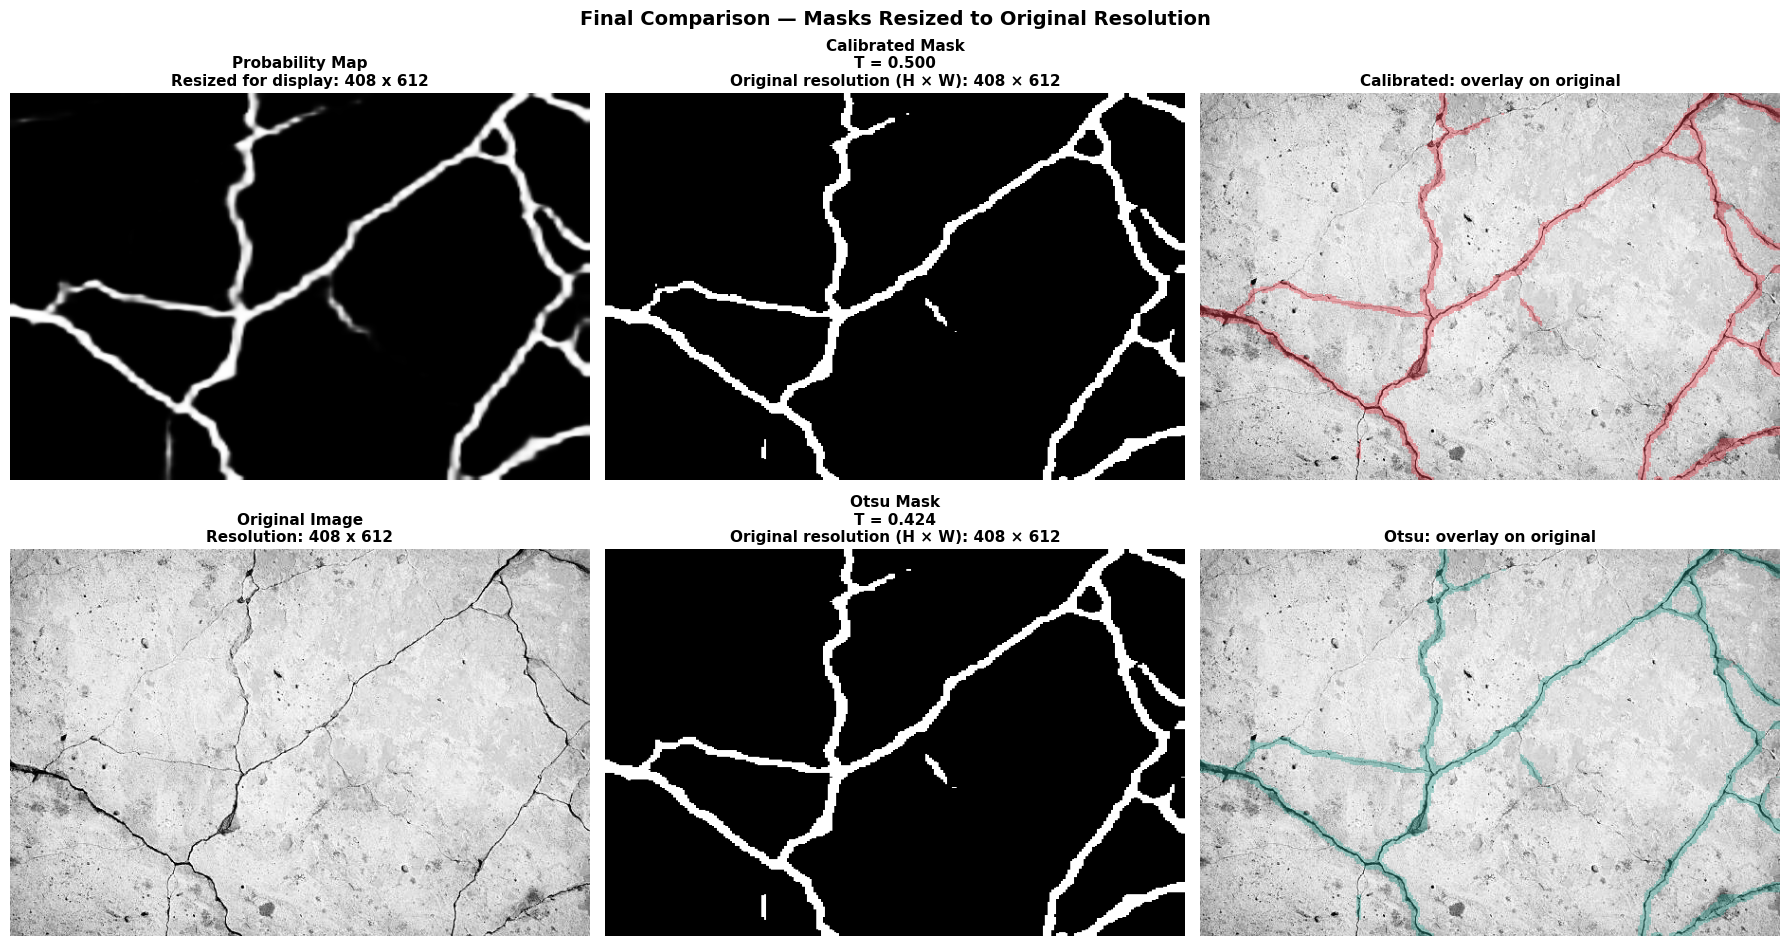


FINAL MASK INFORMATION
Original image          : 408 x 612
Model input             : 256 x 256
Calibrated mask         : 256 x 256 -> 612 x 408
Otsu mask               : 256 x 256 -> 612 x 408
Calibrated threshold    : 0.500
Calibrated crack pixels : 7.80%
Otsu threshold          : 0.424
Otsu crack pixels       : 8.25%

Otsu picked a LOWER threshold -> more pixels classified as crack -> more sensitive

NOTE:
The model prediction is generated at 256 x 256.
The binary masks are resized to the original image resolution using INTER_NEAREST.
The resized masks are then applied directly to the original image.
This keeps the final mask dimensions identical to the original image dimensions.

EXPLICIT HEIGHT × WIDTH CHECK
----------------------------------------------------------------------
Original image       : H=408, W=612
Calibrated mask      : H=408, W=612
Otsu mask            : H=408, W=612
Same H × W as image? : True
----------------------------------------------------------------------

In [15]:
# ============================================================
# 7. FINAL RESULT — RESIZE MASKS TO ORIGINAL IMAGE RESOLUTION
# ============================================================

# The SegFormer model works on a fixed 256x256 input.
# Therefore prob_map, calib_mask and otsu_mask are initially 256x256.
#
# We resize the FINAL BINARY MASKS back to the original image
# resolution before displaying or applying them to the original image.
#
# IMPORTANT:
# Use INTER_NEAREST for binary masks so that values remain exactly
# 0 (background) or 1 (crack). Do not use bilinear interpolation.


# ------------------------------------------------------------
# Step 1: Apply both thresholds to the 256x256 probability map
# ------------------------------------------------------------
calib_mask = (prob_map > calibrated_threshold).astype(np.uint8)
otsu_mask  = (prob_map > otsu_threshold).astype(np.uint8)

print("=" * 70)
print("MASK RESOLUTION CHECK")
print("=" * 70)
print(f"Original image resolution (H × W): {orig_h} × {orig_w}")
print(f"Model input resolution    : {IMG_SIZE} x {IMG_SIZE}")
print(f"Calibrated mask (model) (H × W)   : {calib_mask.shape[0]} × {calib_mask.shape[1]}")
print(f"Otsu mask (model) (H × W)         : {otsu_mask.shape[0]} × {otsu_mask.shape[1]}")


# ------------------------------------------------------------
# Step 2: Resize binary masks to ORIGINAL image resolution
# ------------------------------------------------------------
# cv2.resize expects size as (width, height), hence (orig_w, orig_h).
calib_full = cv2.resize(
    calib_mask,
    (orig_w, orig_h),
    interpolation=cv2.INTER_NEAREST
)

otsu_full = cv2.resize(
    otsu_mask,
    (orig_w, orig_h),
    interpolation=cv2.INTER_NEAREST
)

print(f"Calibrated mask (original) (H × W): {calib_full.shape[0]} × {calib_full.shape[1]}")
print(f"Otsu mask (original)      : {otsu_full.shape[1]} x {otsu_full.shape[0]}")


# ------------------------------------------------------------
# Step 3: Resize probability map ONLY for visualization
# ------------------------------------------------------------
# The actual model prediction is still 256x256.
# This resized probability map is only used so that the visual
# comparison is shown at the same resolution as the original image.
prob_full = cv2.resize(
    prob_map,
    (orig_w, orig_h),
    interpolation=cv2.INTER_LINEAR
)


# ------------------------------------------------------------
# Step 4: Apply the full-resolution masks to the ORIGINAL image
# ------------------------------------------------------------
overlay_calib = np_img.copy()
overlay_calib[calib_full == 1] = [230, 57, 70]
blended_calib = cv2.addWeighted(
    np_img,
    0.6,
    overlay_calib,
    0.4,
    0
)

overlay_otsu = np_img.copy()
overlay_otsu[otsu_full == 1] = [42, 157, 143]
blended_otsu = cv2.addWeighted(
    np_img,
    0.6,
    overlay_otsu,
    0.4,
    0
)


# ------------------------------------------------------------
# Step 5: Display everything at ORIGINAL image resolution
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# ============================================================
# ROW 1 — CALIBRATED THRESHOLD
# ============================================================

axes[0, 0].imshow(
    prob_full,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[0, 0].set_title(
    f"Probability Map\n"
    f"Resized for display: {orig_h} x {orig_w}",
    fontsize=11,
    fontweight="bold"
)
axes[0, 0].axis("off")


axes[0, 1].imshow(
    calib_full,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[0, 1].set_title(
    f"Calibrated Mask\n"
    f"T = {calibrated_threshold:.3f}\n"
    f"Original resolution (H × W): {orig_h} × {orig_w}",
    fontsize=11,
    fontweight="bold"
)
axes[0, 1].axis("off")


axes[0, 2].imshow(blended_calib)
axes[0, 2].set_title(
    "Calibrated: overlay on original",
    fontsize=11,
    fontweight="bold"
)
axes[0, 2].axis("off")


# ============================================================
# ROW 2 — OTSU THRESHOLD
# ============================================================

axes[1, 0].imshow(np_img)
axes[1, 0].set_title(
    f"Original Image\n"
    f"Resolution: {orig_h} x {orig_w}",
    fontsize=11,
    fontweight="bold"
)
axes[1, 0].axis("off")


axes[1, 1].imshow(
    otsu_full,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1, 1].set_title(
    f"Otsu Mask\n"
    f"T = {otsu_threshold:.3f}\n"
    f"Original resolution (H × W): {orig_h} × {orig_w}",
    fontsize=11,
    fontweight="bold"
)
axes[1, 1].axis("off")


axes[1, 2].imshow(blended_otsu)
axes[1, 2].set_title(
    "Otsu: overlay on original",
    fontsize=11,
    fontweight="bold"
)
axes[1, 2].axis("off")


plt.suptitle(
    "Final Comparison — Masks Resized to Original Resolution",
    fontsize=14,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Step 6: Calculate crack-pixel percentage on the
#         ORIGINAL-RESOLUTION masks
# ------------------------------------------------------------
calib_pct = 100.0 * calib_full.sum() / calib_full.size
otsu_pct  = 100.0 * otsu_full.sum() / otsu_full.size


print("\n" + "=" * 70)
print("FINAL MASK INFORMATION")
print("=" * 70)
print(f"Original image          : {orig_h} x {orig_w}")
print(f"Model input             : {IMG_SIZE} x {IMG_SIZE}")
print(f"Calibrated mask         : {calib_mask.shape[1]} x {calib_mask.shape[0]}"
      f" -> {calib_full.shape[1]} x {calib_full.shape[0]}")
print(f"Otsu mask               : {otsu_mask.shape[1]} x {otsu_mask.shape[0]}"
      f" -> {otsu_full.shape[1]} x {otsu_full.shape[0]}")
print(f"Calibrated threshold    : {calibrated_threshold:.3f}")
print(f"Calibrated crack pixels : {calib_pct:.2f}%")
print(f"Otsu threshold          : {otsu_threshold:.3f}")
print(f"Otsu crack pixels       : {otsu_pct:.2f}%")

if otsu_threshold < calibrated_threshold:
    print("\nOtsu picked a LOWER threshold -> more pixels classified as crack -> more sensitive")
else:
    print("\nOtsu picked a HIGHER threshold -> fewer pixels classified as crack -> more conservative")

print("\nNOTE:")
print("The model prediction is generated at 256 x 256.")
print("The binary masks are resized to the original image resolution using INTER_NEAREST.")
print("The resized masks are then applied directly to the original image.")
print("This keeps the final mask dimensions identical to the original image dimensions.")


print("\nEXPLICIT HEIGHT × WIDTH CHECK")
print("-" * 70)
print(f"Original image       : H={orig_h}, W={orig_w}")
print(f"Calibrated mask      : H={calib_full.shape[0]}, W={calib_full.shape[1]}")
print(f"Otsu mask            : H={otsu_full.shape[0]}, W={otsu_full.shape[1]}")
print(f"Same H × W as image? : {calib_full.shape[:2] == np_img.shape[:2]}")
print("-" * 70)



## 8. TEST-TIME AUGMENTATION (TTA) — SCALE INVARIANCE

Runs the same image through the model multiple times with

TEST-TIME AUGMENTATION (TTA)
Running 5 augmented passes through the model...
TTA completed in 0.4s (0.1s per pass)


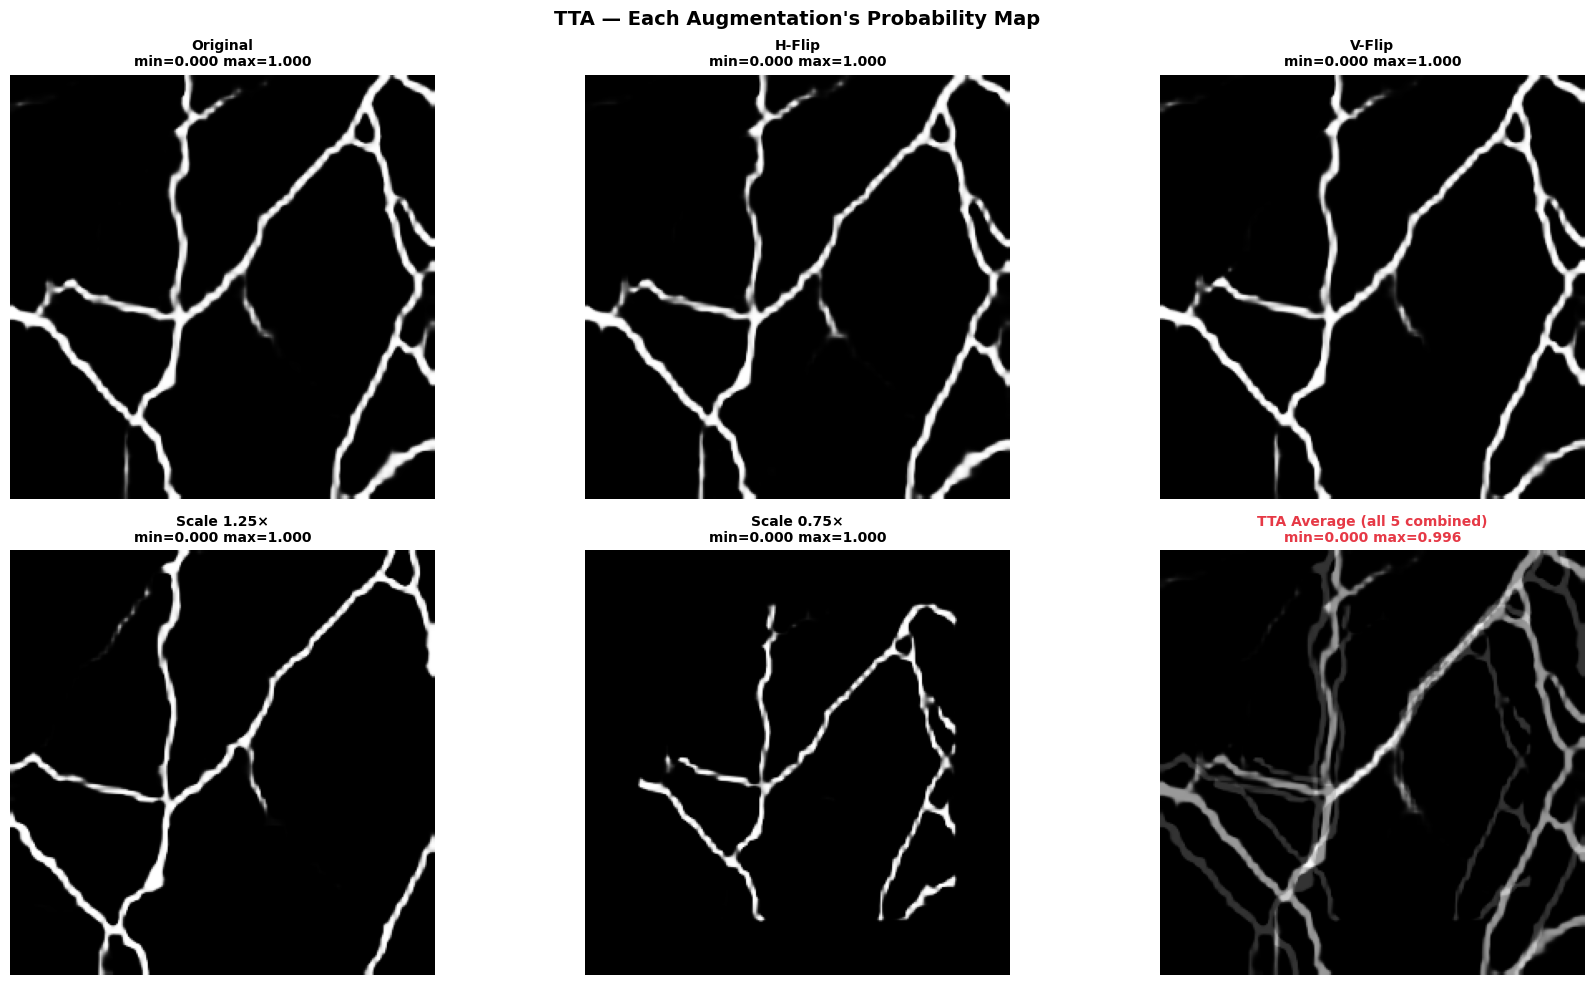


COMPARISON: Single-Pass vs TTA


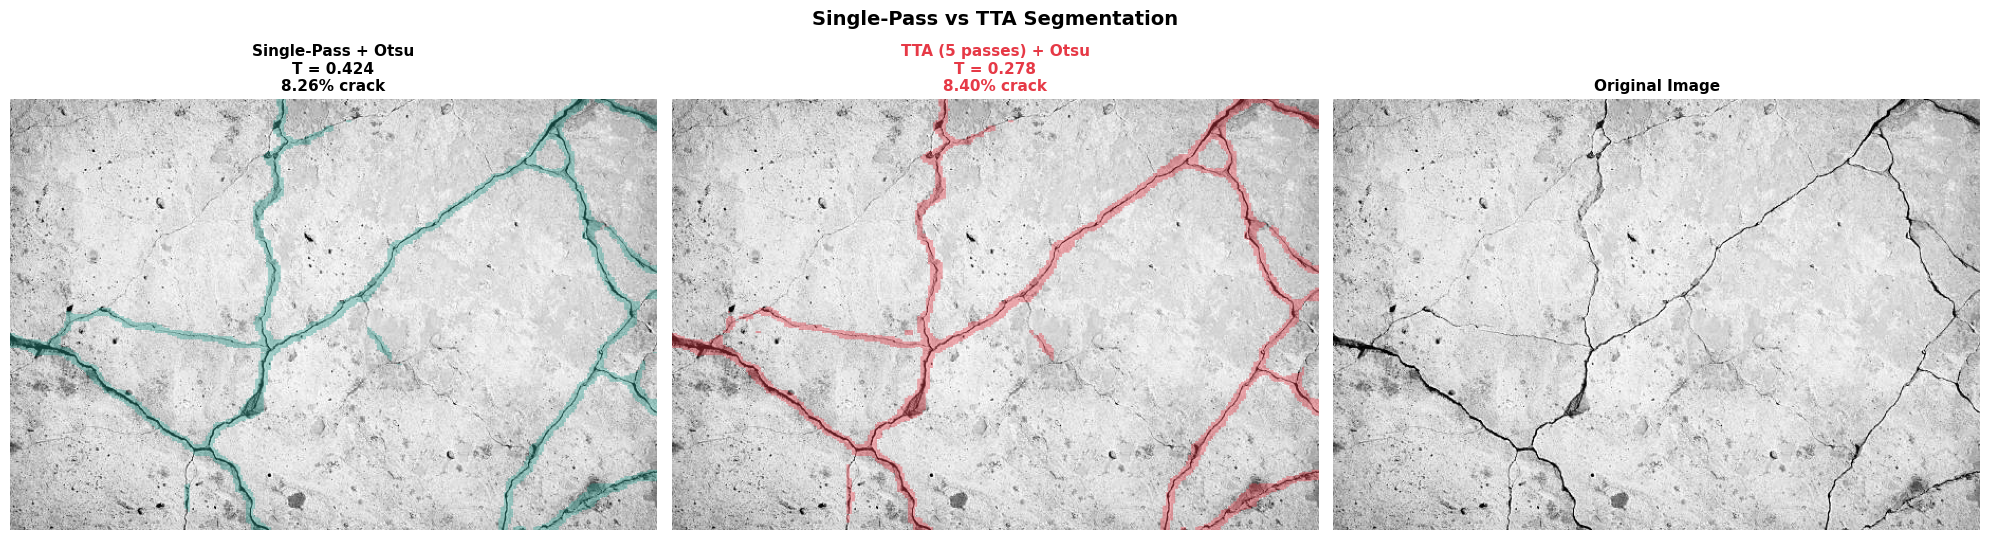


  Single-pass Otsu threshold: 0.424
  TTA Otsu threshold:         0.278
  Single-pass crack pixels:   8.26%
  TTA crack pixels:           8.40%
  Inference time:             0.4s (5 passes)

  HOW TTA WORKS:
    1. Run the SAME image through the SAME model 5 times:
       - Original, horizontal flip, vertical flip, scale 1.25×, scale 0.75×
    2. Each pass produces a probability map
    3. Flipped/scaled maps are reversed back to the original orientation
    4. All 5 maps are AVERAGED → more robust probability estimate
    5. Otsu threshold is applied to the averaged map

  WHY IT HELPS FOR SCALE INVARIANCE:
    - Scale 1.25×: thin cracks become thicker relative to model input,
      so the model detects them more confidently
    - Scale 0.75×: wider context helps the model understand the surrounding area
    - Flips: the model sees crack patterns from multiple orientations
    - Averaging: reduces noise and smooths out prediction inconsistencies

  COST:
    - 5× longer inference tim

In [16]:

# different augmentations, then averages the probability maps.
# Uses the existing: model, DEVICE, IMG_SIZE, binary_logits_from_two_class

@torch.no_grad()
def tta_inference(np_img, model, img_size=IMG_SIZE, device=DEVICE):
    """
    Run TTA with flips + scales on one image.
    Returns the averaged probability map at (img_size × img_size).
    """
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    model.eval()

    def preprocess(image):
        """Resize to model input, normalize, to tensor."""
        t = A.Compose([
            A.Resize(img_size, img_size),
            A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
            ToTensorV2(),
        ])(image=image)["image"]
        return t.unsqueeze(0).to(device)

    def predict(tensor):
        """Run model, return probability map as numpy (H, W)."""
        with torch.amp.autocast(device.type, enabled=(device.type == "cuda")):
            logits = model(pixel_values=tensor).logits
            logits_up = F.interpolate(logits, size=(img_size, img_size),
                                      mode="bilinear", align_corners=False)
            binary_logit = binary_logits_from_two_class(logits_up.float())
            return torch.sigmoid(binary_logit)[0].cpu().numpy()

    # ---- Define TTA augmentations ----
    # Each entry: (name, forward_transform, reverse_transform_on_prob_map)

    tta_configs = []

    # 1. Original (no augmentation)
    tta_configs.append(("Original", lambda img: img, lambda p: p))

    # 2. Horizontal flip
    tta_configs.append(("H-Flip",
                        lambda img: np.fliplr(img).copy(),
                        lambda p: np.fliplr(p).copy()))

    # 3. Vertical flip
    tta_configs.append(("V-Flip",
                        lambda img: np.flipud(img).copy(),
                        lambda p: np.flipud(p).copy()))

    # 4. Scale 1.25× (zoom in — thin cracks become more visible)
    def scale_up(img):
        h, w = img.shape[:2]
        new_h, new_w = int(h * 1.25), int(w * 1.25)
        scaled = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
        # Center crop back to original size
        y_start = (new_h - h) // 2
        x_start = (new_w - w) // 2
        return scaled[y_start:y_start+h, x_start:x_start+w]
    tta_configs.append(("Scale 1.25×", scale_up, lambda p: p))

    # 5. Scale 0.75× (zoom out — wider context)
    def scale_down(img):
        h, w = img.shape[:2]
        new_h, new_w = int(h * 0.75), int(w * 0.75)
        scaled = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
        # Pad back to original size
        pad_top = (h - new_h) // 2
        pad_left = (w - new_w) // 2
        padded = np.zeros_like(img)
        padded[pad_top:pad_top+new_h, pad_left:pad_left+new_w] = scaled
        return padded
    def unpad_scale_down(p):
        # The padded border has meaningless predictions — mask them
        h, w = p.shape
        new_h, new_w = int(h / 0.75 * 0.75), int(w / 0.75 * 0.75)  # recover
        return p  # keep as is — averaged with others, border gets diluted
    tta_configs.append(("Scale 0.75×", scale_down, unpad_scale_down))

    # ---- Run all TTA variants ----
    prob_maps = []
    tta_details = []

    for name, forward_fn, reverse_fn in tta_configs:
        aug_img = forward_fn(np_img)
        tensor = preprocess(aug_img)
        prob = predict(tensor)
        prob_reversed = reverse_fn(prob)
        prob_maps.append(prob_reversed)
        tta_details.append((name, prob_reversed))

    # ---- Average all probability maps ----
    tta_avg = np.mean(prob_maps, axis=0)

    return tta_avg, tta_details


# ============================================================
# RUN TTA
# ============================================================
import time

print("=" * 70)
print("TEST-TIME AUGMENTATION (TTA)")
print("=" * 70)
print(f"Running {5} augmented passes through the model...")

t0 = time.time()
tta_prob_map, tta_details = tta_inference(np_img, model)
tta_avg = tta_prob_map   # <-- moved up here, before it's used below
elapsed = time.time() - t0
print(f"TTA completed in {elapsed:.1f}s ({elapsed/5:.1f}s per pass)")

# ---- Show individual TTA probability maps ----
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (name, prob) in enumerate(tta_details):
    axes[idx].imshow(prob, cmap="gray", vmin=0, vmax=1)
    axes[idx].set_title(f"{name}\nmin={prob.min():.3f} max={prob.max():.3f}",
                        fontsize=10, fontweight="bold")
    axes[idx].axis("off")

# Show the averaged map in the last panel
axes[5].imshow(tta_avg, cmap="gray", vmin=0, vmax=1)
axes[5].set_title(f"TTA Average (all 5 combined)\nmin={tta_avg.min():.3f} max={tta_avg.max():.3f}",
                  fontsize=10, fontweight="bold", color="#E63946")
axes[5].axis("off")

plt.suptitle("TTA — Each Augmentation's Probability Map",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# ---- Compare: single-pass vs TTA ----
print("\n" + "=" * 70)
print("COMPARISON: Single-Pass vs TTA")
print("=" * 70)

# Apply Otsu to both
def apply_otsu(prob):
    prob_u8 = (prob * 255).astype(np.uint8)
    otsu_u8, _ = cv2.threshold(prob_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return otsu_u8 / 255.0

otsu_single = apply_otsu(prob_map)
otsu_tta = apply_otsu(tta_avg)

mask_single = (prob_map > otsu_single).astype(np.uint8)
mask_tta = (tta_avg > otsu_tta).astype(np.uint8)

# Resize to original resolution
mask_single_full = cv2.resize(mask_single, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
mask_tta_full = cv2.resize(mask_tta, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)

# Overlays
overlay_single = np_img.copy()
overlay_single[mask_single_full == 1] = [42, 157, 143]
blended_single = cv2.addWeighted(np_img, 0.6, overlay_single, 0.4, 0)

overlay_tta = np_img.copy()
overlay_tta[mask_tta_full == 1] = [230, 57, 70]
blended_tta = cv2.addWeighted(np_img, 0.6, overlay_tta, 0.4, 0)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].imshow(blended_single)
axes[0].set_title(f"Single-Pass + Otsu\nT = {otsu_single:.3f}\n{100*mask_single.sum()/mask_single.size:.2f}% crack",
                  fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(blended_tta)
axes[1].set_title(f"TTA (5 passes) + Otsu\nT = {otsu_tta:.3f}\n{100*mask_tta.sum()/mask_tta.size:.2f}% crack",
                  fontsize=11, fontweight="bold", color="#E63946")
axes[1].axis("off")

axes[2].imshow(np_img)
axes[2].set_title("Original Image", fontsize=11, fontweight="bold")
axes[2].axis("off")

plt.suptitle("Single-Pass vs TTA Segmentation", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

single_pct = 100 * mask_single.sum() / mask_single.size
tta_pct = 100 * mask_tta.sum() / mask_tta.size

print(f"\n  Single-pass Otsu threshold: {otsu_single:.3f}")
print(f"  TTA Otsu threshold:         {otsu_tta:.3f}")
print(f"  Single-pass crack pixels:   {single_pct:.2f}%")
print(f"  TTA crack pixels:           {tta_pct:.2f}%")
print(f"  Inference time:             {elapsed:.1f}s (5 passes)")

print("""
  HOW TTA WORKS:
    1. Run the SAME image through the SAME model 5 times:
       - Original, horizontal flip, vertical flip, scale 1.25×, scale 0.75×
    2. Each pass produces a probability map
    3. Flipped/scaled maps are reversed back to the original orientation
    4. All 5 maps are AVERAGED → more robust probability estimate
    5. Otsu threshold is applied to the averaged map

  WHY IT HELPS FOR SCALE INVARIANCE:
    - Scale 1.25×: thin cracks become thicker relative to model input,
      so the model detects them more confidently
    - Scale 0.75×: wider context helps the model understand the surrounding area
    - Flips: the model sees crack patterns from multiple orientations
    - Averaging: reduces noise and smooths out prediction inconsistencies

  COST:
    - 5× longer inference time per image
    - No retraining needed — same frozen model weights
    - Typical improvement: +1–3% Dice
""")